In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
from tqdm import tqdm

save_dir = Path("/nas/cee-water/cjgleason/ted/swot-ml/data/owen_reservoirs/Columbia")
metadata_dir = save_dir / "metadata"

gauges = gpd.read_parquet(metadata_dir / "gauges.parquet").set_index('site_id')

subs_df = gpd.read_parquet(metadata_dir / 'subbasins_4km2.parquet')#, columns=['site_id', 'is_gauge', 'is_reservoir', 'uparea_km2', 'outlet_id'])
subs_df.index = subs_df.index.astype(str)

basin_subbasin_dict = subs_df.groupby('outlet_id').apply(lambda g: g.index.tolist(), include_groups=False).to_dict()

In [2]:
subs_df[subs_df['is_reservoir']]

,geometry,area_km2,uparea_km2,original_comid,node_type,is_gauge,is_reservoir,nextdown,outlet_id
site_id,,,,,,,,,
7820000033,"MULTIPOLYGON (((-118.39625 43.72542, -118.3962...",346.951472,2783.801474,78024308,reservoir,False,True,78024295,USGS-14246900
7820000273,"MULTIPOLYGON (((-118.30125 44.00542, -118.3012...",168.535447,1158.927055,78024357,reservoir,False,True,78024290,USGS-14246900
7820000913,"MULTIPOLYGON (((-120.79458 44.09042, -120.7945...",214.088752,7299.500679,78021901,reservoir,False,True,78021889,USGS-14246900
7820001463,"POLYGON ((-122.76125 43.96208, -122.76125 43.9...",140.684704,474.606377,78024327,reservoir,False,True,USGS-14151000,USGS-14246900
7820001573,"POLYGON ((-121.98208 43.74042, -121.98208 43.7...",410.731603,672.042843,78024325,reservoir,False,True,7820003263,USGS-14246900
...,...,...,...,...,...,...,...,...,...
7820069173,"MULTIPOLYGON (((-117.58458 47.64375, -117.5845...",338.805358,15972.659614,78015577,reservoir,False,True,USGS-12433000,USGS-14246900
7820071213,"MULTIPOLYGON (((-119.27375 52.77792, -119.2737...",4254.314835,21140.688130,78006760,reservoir,False,True,7820071293,USGS-14246900
7820071293,"MULTIPOLYGON (((-118.92708 51.69542, -118.9270...",2426.829815,26386.267656,78008362,reservoir,False,True,78008362,USGS-14246900


In [3]:
from pathlib import Path
from data import ZarrBasinStore
store_path = save_dir / 'zarr_store'
store = ZarrBasinStore(store_path)

In [4]:
subs_df['original_comid'] = subs_df.index

# A small % of gauges are dropped if they don't match well.
common_idx = subs_df.index.intersection(gauges.index)
subs_df.loc[common_idx, 'original_comid'] = gauges.loc[common_idx, 'COMID'].astype(str)
subs_df

,geometry,area_km2,uparea_km2,original_comid,node_type,is_gauge,is_reservoir,nextdown,outlet_id
site_id,,,,,,,,,
78026418,"POLYGON ((-110.57958 43.96375, -110.57958 43.9...",70.755417,70.755417,78026418,original,False,False,7820017443,USGS-14246900
78014072,"MULTIPOLYGON (((-118.29875 47.99125, -118.2987...",50.614950,50.614950,78014072,original,False,False,7820034213,USGS-14246900
78015448,"POLYGON ((-119.33458 49.05958, -119.33458 49.0...",25.694601,25.694601,78015448,original,False,False,7820039453,USGS-14246900
78019645,"POLYGON ((-119.56958 47.03458, -119.56958 47.0...",37.039777,37.039777,78019645,original,False,False,7820020163,USGS-14246900
78021658,"POLYGON ((-119.52125 45.96542, -119.51792 45.9...",117.454282,117.454282,78021658,original,False,False,7820052763,USGS-14246900
...,...,...,...,...,...,...,...,...,...
7820069173,"MULTIPOLYGON (((-117.58458 47.64375, -117.5845...",338.805358,15972.659614,7820069173,reservoir,False,True,USGS-12433000,USGS-14246900
7820071213,"MULTIPOLYGON (((-119.27375 52.77792, -119.2737...",4254.314835,21140.688130,7820071213,reservoir,False,True,7820071293,USGS-14246900
7820071293,"MULTIPOLYGON (((-118.92708 51.69542, -118.9270...",2426.829815,26386.267656,7820071293,reservoir,False,True,78008362,USGS-14246900


In [85]:
subs_df['is_reservoir'].sum()

99

wse  wse_u  wse_std     wse_e  dv_staticPLD  \
lake_id    date                                                           
7820000022 2023-08-29  1063.491  0.077    0.282  0.621787      0.000000   
           2023-09-08  1063.656  0.094    0.345  0.655001      0.008467   
           2023-09-21  1063.050  0.077    0.112  0.565366     -0.022619   
           2023-12-01  1065.444  0.181    0.255  0.631626      0.100189   
           2023-12-12  1065.321  0.072    0.255  0.609405      0.093883   
...                         ...    ...      ...       ...           ...   
7820077482 2025-02-01   989.606  0.125    0.759  1.377993      0.492676   
           2025-03-15   993.255  0.019    0.135  1.151410      2.283230   
           2025-03-24   993.273  0.008    0.112  1.148811      2.292065   
           2025-04-05   993.820  0.007    0.081  1.146197      2.560476   
           2025-04-26   993.753  0.008    0.088  1.146720      2.527591   

                       dv_e_staticPLD  dv_SWOTAE  dv_e_SWOTAE  
lake_id    date                                                
7820000022 2023-08-29        0.031898   0.000000     0.026995  
           2023-09-08        0.033602   0.007222     0.028888  
           2023-09-21        0.029003  -0.018737     0.023505  
           2023-12-01        0.032402   0.092748     0.032570  
           2023-12-12        0.031262   0.086441     0.031111  
...                               ...        ...          ...  
7820077482 2025-02-01        0.676180   0.237673     0.437290  
           2025-03-15        0.564996   2.464777     1.040104  
           2025-03-24        0.563720   2.481067     1.041078  
           2025-04-05        0.562438   3.000793     1.139395  
           2025-04-26        0.562694   2.934535     1.127573  

[99207 rows x 8 columns]

39         7820000022
49         7820000022
62         7820000022
133        7820000022
144        7820000022
              ...    
2058001    7820077482
2058043    7820077482
2058052    7820077482
2058064    7820077482
2058085    7820077482
Name: lake_id, Length: 99207, dtype: object

In [45]:
jida_dir = Path("/nas/cee-water/cjgleason/ted/LakeSPvC_ts_for_Ted/daily_ts_from_LakeSPvC")
pfaf3s = subs_df[subs_df['is_reservoir']].index.str[0:3].unique()

res_dfs = []
for pfaf3 in pfaf3s:
    res_data = pd.read_csv(jida_dir / f'basin_{pfaf3}_daily_timeseries.csv')
    res_data['lake_id'] = res_data['lake_id'].astype(str)
    res_data.dropna(axis=0, subset='wse', inplace=True)
    res_data.drop(columns=['dv_3DLAKES','dv_e_3DLAKES'], inplace=True)
    res_data.set_index(['lake_id','date'], inplace=True)
    res_dfs.append(res_data)

res_df = pd.concat(res_dfs)
res_df

wse  wse_u  wse_std     wse_e  dv_staticPLD  \
lake_id    date                                                           
7820000022 2023-08-29  1063.491  0.077    0.282  0.621787      0.000000   
           2023-09-08  1063.656  0.094    0.345  0.655001      0.008467   
           2023-09-21  1063.050  0.077    0.112  0.565366     -0.022619   
           2023-12-01  1065.444  0.181    0.255  0.631626      0.100189   
           2023-12-12  1065.321  0.072    0.255  0.609405      0.093883   
...                         ...    ...      ...       ...           ...   
7820077482 2025-02-01   989.606  0.125    0.759  1.377993      0.492676   
           2025-03-15   993.255  0.019    0.135  1.151410      2.283230   
           2025-03-24   993.273  0.008    0.112  1.148811      2.292065   
           2025-04-05   993.820  0.007    0.081  1.146197      2.560476   
           2025-04-26   993.753  0.008    0.088  1.146720      2.527591   

                       dv_e_staticPLD  dv_SWOTAE  dv_e_SWOTAE  
lake_id    date                                                
7820000022 2023-08-29        0.031898   0.000000     0.026995  
           2023-09-08        0.033602   0.007222     0.028888  
           2023-09-21        0.029003  -0.018737     0.023505  
           2023-12-01        0.032402   0.092748     0.032570  
           2023-12-12        0.031262   0.086441     0.031111  
...                               ...        ...          ...  
7820077482 2025-02-01        0.676180   0.237673     0.437290  
           2025-03-15        0.564996   2.464777     1.040104  
           2025-03-24        0.563720   2.481067     1.041078  
           2025-04-05        0.562438   3.000793     1.139395  
           2025-04-26        0.562694   2.934535     1.127573  

[99207 rows x 8 columns]

<Axes: xlabel='date'>

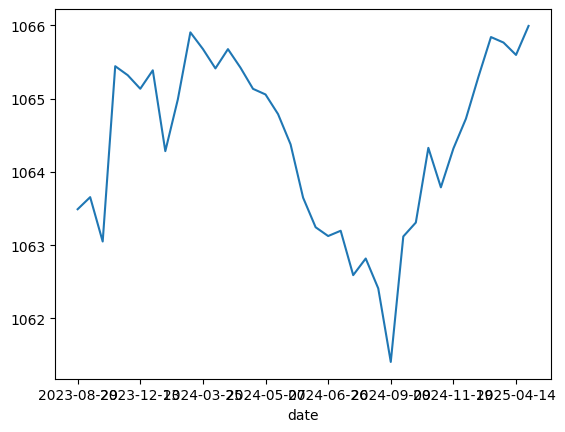

In [46]:
res_df.xs('7820000022', level='lake_id')['wse'].plot()

In [ ]:
list(res_df)

In [78]:
batch_df_list[0].index.name

In [80]:
def get_swot_res(lake_id):
    try:
        res_ix = res_df.xs(lake_id, level='lake_id')
    except KeyError:
        return None
    
    res_ix.index = pd.to_datetime(res_ix.index).tz_localize('UTC')
    res_ix.index.name = 'date'
    
    return res_ix.copy()

    

BATCH_SIZE = 1000
batches = []
for basin_id, basin_group in subs_df.groupby('outlet_id'):
    basin_subs = basin_subbasin_dict[basin_id]
    n_subs = len(basin_subs)

    for i in range(0, n_subs, BATCH_SIZE):
        batch_subs = basin_subs[i : i + BATCH_SIZE]
        batches.append((basin_id, batch_subs))

BATCH_SIZE = 1000
batches = []
for basin_id, basin_group in subs_df.groupby('outlet_id'):
    basin_subs = basin_subbasin_dict[basin_id]
    n_subs = len(basin_subs)

    for i in range(0, n_subs, BATCH_SIZE):
        batch_subs = basin_subs[i : i + BATCH_SIZE]
        batches.append((basin_id, batch_subs))

        
# Iterate over basins (distinct Zarr stores)
for basin_id, batch_subs in tqdm(batches):
    basin_subs = basin_subbasin_dict[basin_id]
    batch_df_list = []
    for subbasin in batch_subs:
        comid = subs_df.loc[subbasin]['original_comid']

        site_df = get_swot_res(comid)
            
        if site_df is not None and not site_df.empty:
            site_df['subbasin'] = subbasin
            batch_df_list.append(site_df)
            
    # If the whole batch is empty, we technically don't need to write anything 
    # since the zarr was initialized with NaNs/empty).
    if batch_df_list:
        print(len(batch_df_list))
        batch_df = pd.concat(batch_df_list)
        store.write_batch_data(basin_id, batch_df, basin_subs, batch_subs)

 67%|██████▋   | 2/3 [00:00<00:00,  5.48it/s]

82


100%|██████████| 3/3 [00:05<00:00,  1.74s/it]


In [ ]:
store.compute_and_store_stats()

/nas/cee-water/cjgleason/ted/swot-ml/.venv/lib/python3.11/site-packages/distributed/node.py:187: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 38969 instead
  warnings.warn(


Dask Dashboard: http://127.0.0.1:38969/status


Processing Basins:   0%|          | 0/1 [00:00<?, ?it/s]